# 1.7 - Clustering the particles that never cross 2.5N

About **2.3% of the particles (~356,000) never cross 2.5N** (status `no_cross`)
and are left out of 1.5 / v3. This notebook clusters them on their own,
step by step, with the same tools as v3.1.5:

1. read their daily tracks from all stores (once, then cached);
2. explore where they are released, how far and where they go;
3. choose and build the features;
4. K sweep: how many separated pathways, and do they come back in
   independent fits;
5. final fit: clusters, pathways, shares;
6. hierarchical view (tree + map);
7. real tracks per pathway;
8. seasonality (release month).

**What they are (all 356,541 particles, 2026-10-22):** released in two areas -
the Pará estuary (~48.7-48.2W, 1.5S-0.5S) and the Amazon channels north of
Marajó Island (~51-49W, 0-1.5N) - mostly in July-November (Aug and Sep ~23%
each). They move little: median distance from release ~35 km at day 30,
~55 km at day 120, ~145 km at day 184; 41% ever get 200 km and 12% 300 km
away (section 2).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # project root: config.py, pipeline.py
import numpy as np
import pandas as pd
import config as C
import pipeline as P
print("project root:", C.PROJECT_ROOT)
print(f"crossing: {C.LAT_CROSS} N | radii (km): {C.RADII_KM}")

import time
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
from joblib import Parallel, delayed
from sklearn.cluster import MiniBatchKMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

project root: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/kmeans_radius
crossing: 2.5 N | radii (km): [200, 500, 1000, 1500, 2000]


In [2]:
DAYS_NC = [15, 30, 60, 90, 120, 150, 180]   # positions at these days after release are the features
DAY_WEIGHTS_NC = None            # None = every day equal; or {15: .., 30: .., ...}
K_SWEEP = [5, 10, 15, 20, 30, 40, 60, 80]
SEEDS = [42, 1, 7]               # independent fits, each on a different random 80% of the particles
PATHWAY_SEP_KM = 50              # two pathways differ if their tracks are >= this far apart (mean over DAYS_NC)
MATCH_KM = 25                    # a pathway is reproduced if another fit has one within this distance
K = None                         # final K; None -> chosen from the sweep
REBUILD_CACHE = False            # True -> re-read the tracks from all stores
SAVE_MODEL = False

## 1. Daily tracks of the never-crossing particles

They are listed in `features.parquet` (status `no_cross`, with `store` /
`row` / `traj`). Their tracks are read from every store, one position per day
(every 4th 6-hourly output), and cached in `data/no_cross/`, so later runs
skip this step (set `REBUILD_CACHE = True` to redo it).

In [3]:
NC_DIR = C.DATA_DIR / "no_cross"; NC_DIR.mkdir(exist_ok=True)
CACHE_TRK, CACHE_META = NC_DIR / "daily_tracks.npz", NC_DIR / "meta.parquet"
N_DAYS = 185                                   # days 0 .. 184 after release

def read_store(path, rows, trajs):
    ds = xr.open_zarr(path)
    got = ds.trajectory.values[rows]
    assert np.array_equal(got, trajs), f"{path.name}: Parcels IDs do not match - re-run 01"
    out = []
    for v in ("lat", "lon"):
        a = ds[v].values[rows][:, ::4][:, :N_DAYS].astype(np.float32)
        if a.shape[1] < N_DAYS:
            a = np.pad(a, ((0, 0), (0, N_DAYS - a.shape[1])), constant_values=np.nan)
        out.append(a)
    t0 = ds.time.values[rows, 0]
    return out[0], out[1], t0

if REBUILD_CACHE or not CACHE_TRK.exists():
    t0_ = time.time()
    f = pd.read_parquet(C.FEATURES_FILE, columns=["trajectory_id", "store", "row", "traj", "status"])
    nc = f[f.status == "no_cross"].drop(columns="status").reset_index(drop=True); del f
    paths = C.store_paths_by_name()
    groups = list(nc.groupby("store", observed=True))
    res = Parallel(n_jobs=int(os.environ.get("SLURM_CPUS_PER_TASK", 16)), backend="loky")(
        delayed(read_store)(paths[name], g.row.to_numpy(), g.traj.to_numpy()) for name, g in groups)
    meta = pd.concat([g for _, g in groups], ignore_index=True)
    LAT = np.concatenate([r[0] for r in res]); LON = np.concatenate([r[1] for r in res])
    meta["release_time"] = pd.to_datetime(np.concatenate([r[2] for r in res]))
    np.savez_compressed(CACHE_TRK, lat=LAT, lon=LON)
    meta.to_parquet(CACHE_META, index=False)
    print(f"read {len(meta):,} tracks from {len(groups)} stores in {(time.time() - t0_) / 60:.1f} min")
else:
    _z = np.load(CACHE_TRK); LAT, LON = _z["lat"], _z["lon"]
    meta = pd.read_parquet(CACHE_META)
    print("loaded cache:", CACHE_TRK)
# a deleted / missing position keeps the last known one (tracks are 185 days for all of them)
LAT = pd.DataFrame(LAT).ffill(axis=1).to_numpy(np.float32)
LON = pd.DataFrame(LON).ffill(axis=1).to_numpy(np.float32)
meta["release_month"] = meta.release_time.dt.month
print(f"{len(meta):,} never-crossing particles, {LAT.shape[1]} daily positions each")

/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/coding/times.py:650: RuntimeWarning: invalid value encountered in cast
  flat_num = flat_num.astype(np.int64)
/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/coding/times.py:650: RuntimeWarning: invalid value encountered in cast
  flat_num = flat_num.astype(np.int64)


/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/coding/times.py:650: RuntimeWarning: invalid value encountered in cast
  flat_num = flat_num.astype(np.int64)


/work/bk1450/b383184/conda/envs/parcels_3.1.2/lib/python3.13/site-packages/xarray/coding/times.py:650: RuntimeWarning: invalid value encountered in cast
  flat_num = flat_num.astype(np.int64)


read 356,541 tracks from 1534 stores in 2.3 min


356,541 never-crossing particles, 185 daily positions each


## 2. Explore: where are they released, how far and where do they go?

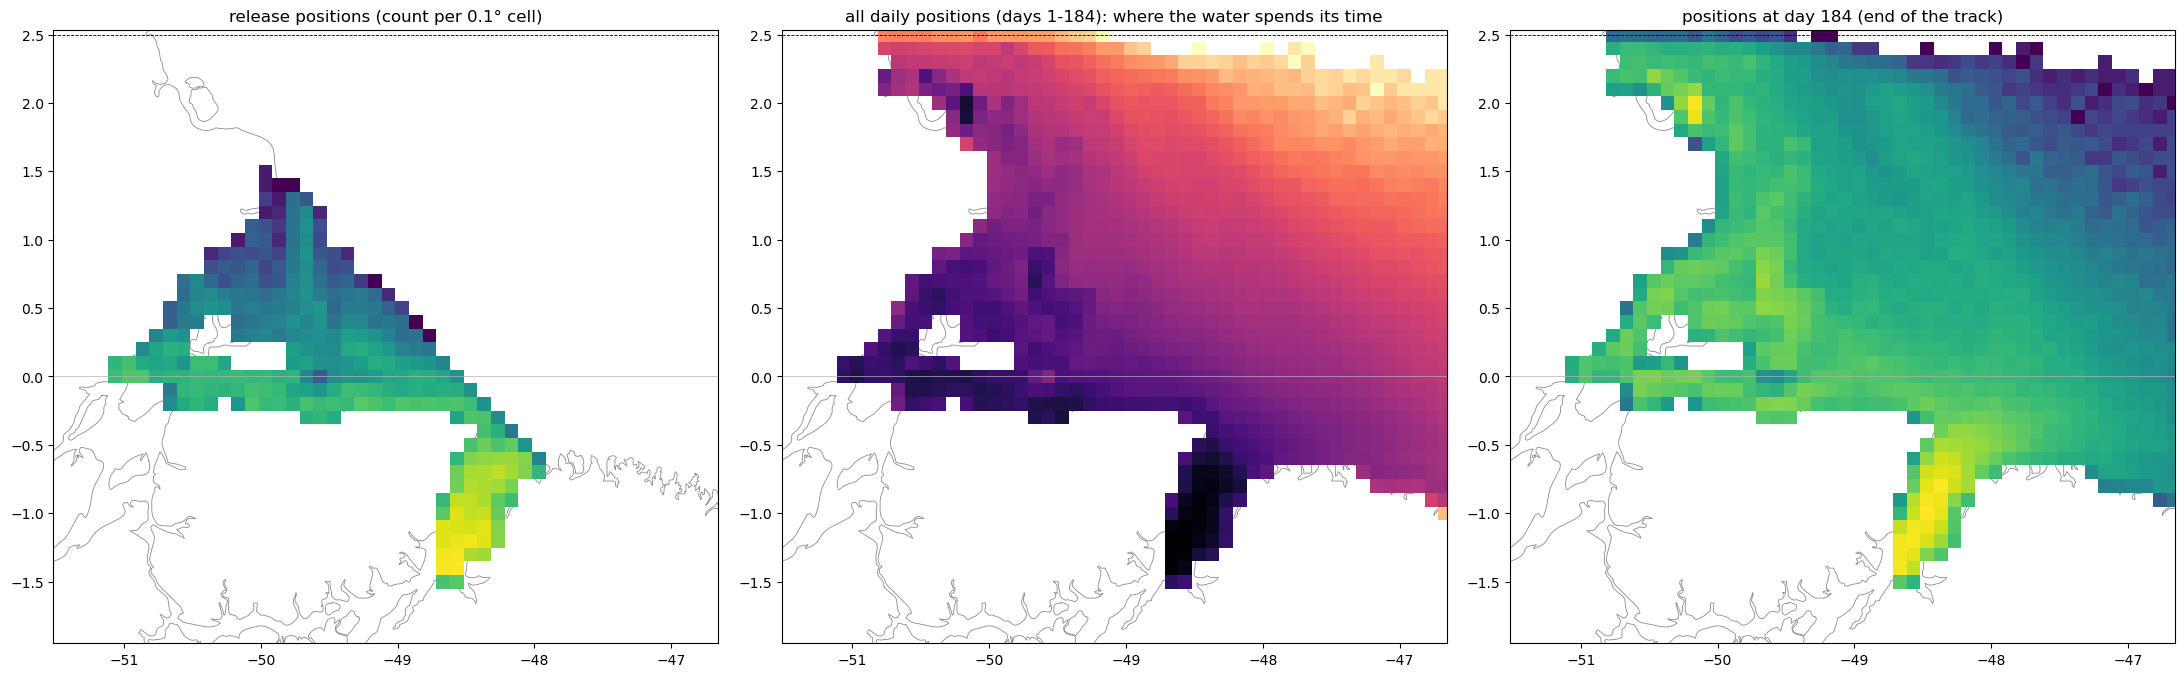

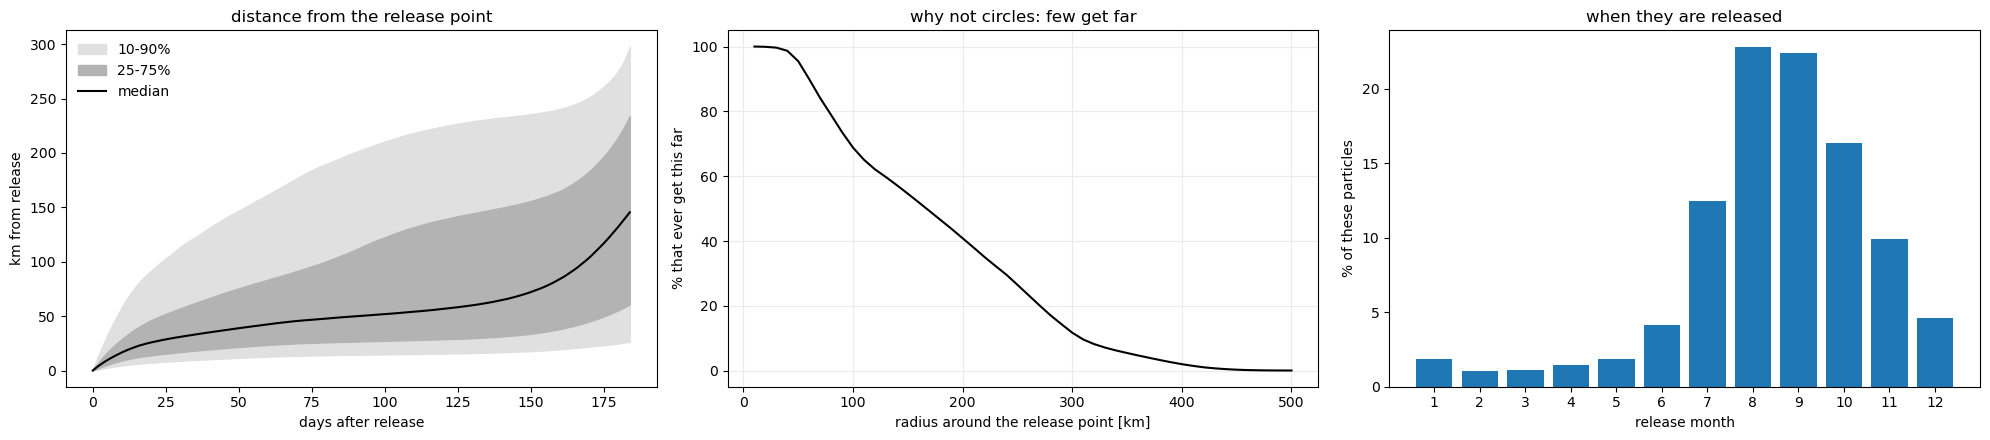

ever  50 km from release:  95.5%
ever 100 km from release:  68.8%
ever 200 km from release:  40.9%
ever 300 km from release:  11.8%


In [4]:
_coast = []
for geom in cfeature.COASTLINE.with_scale("10m").geometries():
    for line in getattr(geom, "geoms", [geom]):
        x, y = np.asarray(line.xy[0]), np.asarray(line.xy[1])
        if ((x > -56) & (x < -40) & (y > -5) & (y < 8)).any():
            _coast.append((x, y))
ZOOM = (np.nanpercentile(LON, .5) - .5, np.nanpercentile(LON, 99.5) + .5,
        np.nanpercentile(LAT, .5) - .5, np.nanpercentile(LAT, 99.5) + .5)
def draw_coast(ax):
    for x, y in _coast:
        ax.plot(x, y, "-", color="0.55", lw=.6, zorder=0)
    ax.axhline(C.LAT_CROSS, color="k", ls="--", lw=.6); ax.axhline(0, color="0.7", lw=.5)
    ax.set_xlim(ZOOM[0], ZOOM[1]); ax.set_ylim(ZOOM[2], ZOOM[3]); ax.set_aspect("equal")

dist = P.haversine_km(LAT[:, :1], LON[:, :1], LAT, LON)          # km from release, every day
from matplotlib.colors import LogNorm
lon_b = np.arange(ZOOM[0], ZOOM[1] + .1, .1); lat_b = np.arange(ZOOM[2], ZOOM[3] + .1, .1)
fig, ax = plt.subplots(1, 3, figsize=(22, 6.5))
draw_coast(ax[0])
h0 = np.histogram2d(LON[:, 0], LAT[:, 0], bins=[lon_b, lat_b])[0].T
ax[0].pcolormesh(lon_b, lat_b, np.where(h0 > 0, h0, np.nan), norm=LogNorm(), cmap="viridis")
ax[0].set_title("release positions (count per 0.1° cell)")
draw_coast(ax[1])
ha = np.histogram2d(LON[:, 1:].ravel(), LAT[:, 1:].ravel(), bins=[lon_b, lat_b])[0].T
ax[1].pcolormesh(lon_b, lat_b, np.where(ha > 0, ha, np.nan), norm=LogNorm(), cmap="magma_r")
ax[1].set_title("all daily positions (days 1-184): where the water spends its time")
draw_coast(ax[2])
he = np.histogram2d(LON[:, -1], LAT[:, -1], bins=[lon_b, lat_b])[0].T
ax[2].pcolormesh(lon_b, lat_b, np.where(he > 0, he, np.nan), norm=LogNorm(), cmap="viridis")
ax[2].set_title("positions at day 184 (end of the track)")
fig.tight_layout(); plt.show()

days = np.arange(LAT.shape[1])
q = np.nanpercentile(dist, [10, 25, 50, 75, 90], axis=0)
fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
ax[0].fill_between(days, q[0], q[4], color="0.88", label="10-90%")
ax[0].fill_between(days, q[1], q[3], color="0.7", label="25-75%")
ax[0].plot(days, q[2], "k-", label="median")
ax[0].set_xlabel("days after release"); ax[0].set_ylabel("km from release"); ax[0].legend(frameon=False)
ax[0].set_title("distance from the release point")
R = np.arange(10, 501, 10)
ax[1].plot(R, [100 * (np.nanmax(dist, 1) >= r).mean() for r in R], "k-")
ax[1].set_xlabel("radius around the release point [km]"); ax[1].set_ylabel("% that ever get this far")
ax[1].set_title("why not circles: few get far"); ax[1].grid(color="0.92")
mc = meta.release_month.value_counts().reindex(range(1, 13), fill_value=0)
ax[2].bar(mc.index, 100 * mc / mc.sum(), color="tab:blue"); ax[2].set_xticks(range(1, 13))
ax[2].set_xlabel("release month"); ax[2].set_ylabel("% of these particles")
ax[2].set_title("when they are released")
fig.tight_layout(); plt.show()
for r in (50, 100, 200, 300):
    print(f"ever {r:3d} km from release: {100 * (np.nanmax(dist, 1) >= r).mean():5.1f}%")

## 3. Features: positions at fixed days after release

The 2.5N-crossing clock and circles of v3 do not fit these particles: they
never cross, and few move far (see the curve above - circles of 100-200 km
would leave a quarter to a half of them as `partial`). But **all their tracks
run the full 185 days**, so the positions at fixed days after release exist
for every particle - no stand-ins - and also record **how long the water
stays** near the estuary, which is the main thing that differs between them.

Features: `[lat, lon]` at the days in `DAYS_NC`, each column standardized
(mean 0, std 1) and optionally weighted per day (`DAY_WEIGHTS_NC`), as in v3.
No balanced sampling: all ~356,000 particles fit in one k-means run.

In [5]:
day_idx = np.array(DAYS_NC)
X = np.column_stack([a for d in day_idx for a in (LAT[:, d], LON[:, d])]).astype(np.float64)
ok = np.isfinite(X).all(axis=1)
print(f"{ok.sum():,} of {len(X):,} particles have all features")
X, meta_ok = X[ok], meta[ok].reset_index(drop=True)
LAT_ok, LON_ok = LAT[ok], LON[ok]
wd = DAY_WEIGHTS_NC or {d: 1.0 for d in DAYS_NC}
Wd = np.array([np.sqrt(wd[d]) for d in DAYS_NC for _ in range(2)])
print("days:", DAYS_NC, "| weights:", wd)

def track_dist(A, B):            # mean haversine distance between two sets of tracks over DAYS_NC (km)
    nd = A.shape[1] // 2
    return sum(P.haversine_km(A[:, None, 2*j], A[:, None, 2*j+1], B[None, :, 2*j], B[None, :, 2*j+1])
               for j in range(nd)) / nd

def fit_k(k, rows, seed, n_init=10):
    sc = StandardScaler().fit(X[rows])
    km = MiniBatchKMeans(n_clusters=k, random_state=seed, batch_size=10000, n_init=n_init,
                         max_iter=300).fit(sc.transform(X[rows]) * Wd)
    cent = pd.DataFrame(X[rows]).groupby(km.labels_).mean().reindex(range(k)).to_numpy()
    return km, sc, cent

def pathways(cent):
    g = fcluster(linkage(squareform(track_dist(cent, cent), checks=False), "complete"),
                 t=PATHWAY_SEP_KM, criterion="distance") - 1
    return g, np.array([cent[g == i].mean(axis=0) for i in range(g.max() + 1)])

356,541 of 356,541 particles have all features


days: [15, 30, 60, 90, 120, 150, 180] | weights: {15: 1.0, 30: 1.0, 60: 1.0, 90: 1.0, 120: 1.0, 150: 1.0, 180: 1.0}


## 4. K sweep: how many separated pathways, and are they reproducible?

For each K, three fits on three different random 80% subsets (seeds
`SEEDS`). Centroids closer than `PATHWAY_SEP_KM` (mean over the days) are
grouped into one pathway; a pathway counts as **reproducible** if a pathway
within `MATCH_KM` appears in both other fits. The thresholds are smaller than
in v3 (400 / 200 km) because these particles move ~50-300 km in total.

K=  5: 5 (3 reproducible), 5 (3 reproducible), 5 (3 reproducible)


K= 10: 8 (5 reproducible), 8 (5 reproducible), 8 (5 reproducible)


K= 15: 10 (5 reproducible), 11 (7 reproducible), 10 (5 reproducible)


K= 20: 14 (8 reproducible), 13 (8 reproducible), 14 (9 reproducible)


K= 30: 16 (9 reproducible), 17 (10 reproducible), 18 (11 reproducible)


K= 40: 22 (11 reproducible), 22 (12 reproducible), 22 (10 reproducible)


K= 60: 29 (17 reproducible), 28 (16 reproducible), 28 (19 reproducible)


K= 80: 35 (22 reproducible), 38 (27 reproducible), 35 (23 reproducible)


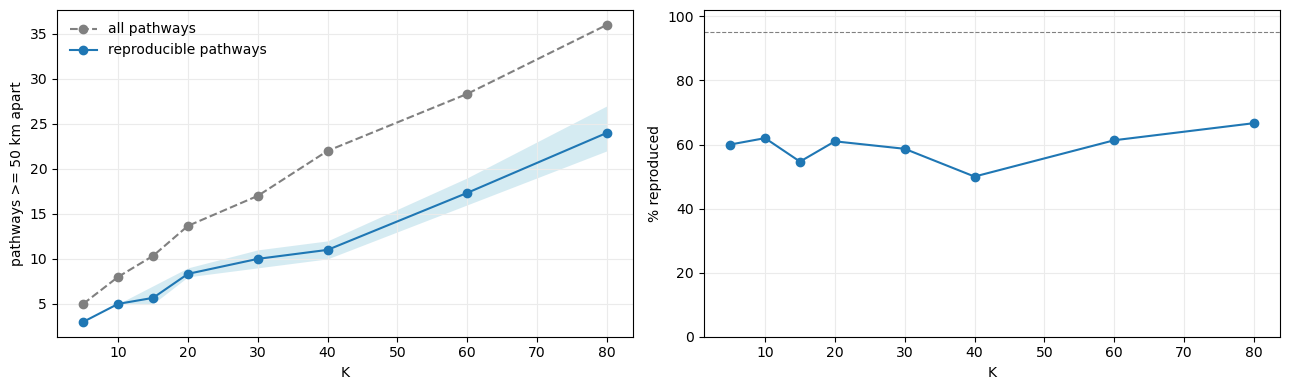

       p    rp  rpmin  rpmax     r
K                                 
5    5.0   3.0      3      3  60.0
10   8.0   5.0      5      5  62.0
15  10.3   5.7      5      7  54.7
20  13.7   8.3      8      9  61.0
30  17.0  10.0      9     11  58.7
40  22.0  11.0     10     12  50.0
60  28.3  17.3     16     19  61.3
80  36.0  24.0     22     27  66.7
suggested K = 80: 24.0 reproducible pathways (67% reproduced)
K used below: 80


In [6]:
rows_all = np.arange(len(X))
runs, recs = {}, []
for k in K_SWEEP:
    for s in SEEDS:
        rows = np.random.default_rng(s).choice(rows_all, int(.8 * len(rows_all)), replace=False)
        km_s, sc_s, cent = fit_k(k, rows, s)
        g, pt = pathways(cent)
        runs[(k, s)] = pt
        recs.append(dict(K=k, seed=s, pathways=len(pt)))
    for s in SEEDS:
        ok_ = np.all([track_dist(runs[(k, s)], runs[(k, o)]).min(axis=1) < MATCH_KM for o in SEEDS if o != s], axis=0)
        r = next(r for r in recs if r["K"] == k and r["seed"] == s)
        r["reproduced_%"] = round(100 * ok_.mean()); r["reproducible"] = int(ok_.sum())
    print(f"K={k:3d}: " + ", ".join(f"{r['pathways']} ({r['reproducible']} reproducible)"
                                    for r in recs if r["K"] == k), flush=True)
sweep = pd.DataFrame(recs)
s_ = sweep.groupby("K").agg(p=("pathways", "mean"), rp=("reproducible", "mean"), rpmin=("reproducible", "min"),
                            rpmax=("reproducible", "max"), r=("reproduced_%", "mean"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(s_.index, s_.p, "o--", color="0.5", label="all pathways")
ax[0].fill_between(s_.index, s_.rpmin, s_.rpmax, color="lightblue", alpha=.5, lw=0)
ax[0].plot(s_.index, s_.rp, "o-", color="tab:blue", label="reproducible pathways")
ax[0].set_xlabel("K"); ax[0].set_ylabel(f"pathways >= {PATHWAY_SEP_KM} km apart"); ax[0].legend(frameon=False)
ax[1].plot(s_.index, s_.r, "o-", color="tab:blue"); ax[1].axhline(95, color="0.5", ls="--", lw=.8)
ax[1].set_xlabel("K"); ax[1].set_ylabel("% reproduced"); ax[1].set_ylim(0, 102)
for a in ax: a.grid(color="0.92")
fig.tight_layout(); plt.show()
good = s_[s_.r >= 95]
K_AUTO = int((good if len(good) else s_).sort_values(["rp", "r"], ascending=[False, False]).index[0])
print(s_.round(1).to_string())
print(f"suggested K = {K_AUTO}: {s_.loc[K_AUTO, 'rp']:.1f} reproducible pathways ({s_.loc[K_AUTO, 'r']:.0f}% reproduced)")
if K is None:
    K = K_AUTO
print("K used below:", K)

## 5. Final fit: clusters, pathways and their shares

Fit on all particles. Every particle gets a cluster, so the shares are the
real ones directly (no balanced sample here).

In [7]:
km, scaler, cent_deg = fit_k(K, rows_all, SEEDS[0], n_init=20)
labels = km.labels_
sizes = np.bincount(labels, minlength=K)
PATH_OF, ptrack = pathways(cent_deg)
n_path = len(ptrack)
share_cl = 100 * sizes / sizes.sum()
share = np.array([share_cl[PATH_OF == i].sum() for i in range(n_path)])
rel_lon = pd.Series(LON_ok[:, 0]).groupby(labels).mean().reindex(range(K)).to_numpy()
rel_lat = pd.Series(LAT_ok[:, 0]).groupby(labels).mean().reindex(range(K)).to_numpy()
def cl_track(c):                 # release point -> positions at DAYS_NC
    return np.r_[rel_lon[c], cent_deg[c, 1::2]], np.r_[rel_lat[c], cent_deg[c, 0::2]]
def pw_track(i):                 # pathway mean track weighted by cluster size
    m = PATH_OF == i
    tr = np.average(cent_deg[m], axis=0, weights=sizes[m])
    return np.r_[np.average(rel_lon[m], weights=sizes[m]), tr[1::2]], np.r_[np.average(rel_lat[m], weights=sizes[m]), tr[0::2]]
end_km = np.array([P.haversine_km(pw_track(i)[1][0], pw_track(i)[0][0], pw_track(i)[1][-1], pw_track(i)[0][-1])
                   for i in range(n_path)])                   # release -> last day, km
ptab = pd.DataFrame({"clusters": np.bincount(PATH_OF, minlength=n_path), "% of particles": share.round(2),
                     f"lat day {DAYS_NC[-1]}": [pw_track(i)[1][-1].round(2) for i in range(n_path)],
                     f"lon day {DAYS_NC[-1]}": [pw_track(i)[0][-1].round(2) for i in range(n_path)],
                     f"km from release at day {DAYS_NC[-1]}": end_km.round(0)},
                    index=pd.Index(range(n_path), name="pathway"))
print(f"fit K={K} on {len(X):,} particles | {n_path} pathways >= {PATHWAY_SEP_KM} km apart | sizes {sizes.min()}..{sizes.max()}")
ptab.sort_values("% of particles", ascending=False)

fit K=80 on 356,541 particles | 37 pathways >= 50 km apart | sizes 488..14987


,clusters,% of particles,lat day 180,lon day 180,km from release at day 180
pathway,,,,,
26,10,28.86,-0.94,-48.46,19.0
28,5,12.57,-0.32,-48.03,98.0
30,5,7.20,0.17,-48.19,140.0
29,3,4.31,0.43,-49.33,190.0
14,2,3.80,0.70,-49.68,241.0
27,2,3.04,0.02,-46.70,232.0
10,3,2.99,0.39,-50.20,50.0
12,2,2.88,0.28,-50.12,201.0
15,2,2.75,0.21,-49.91,217.0


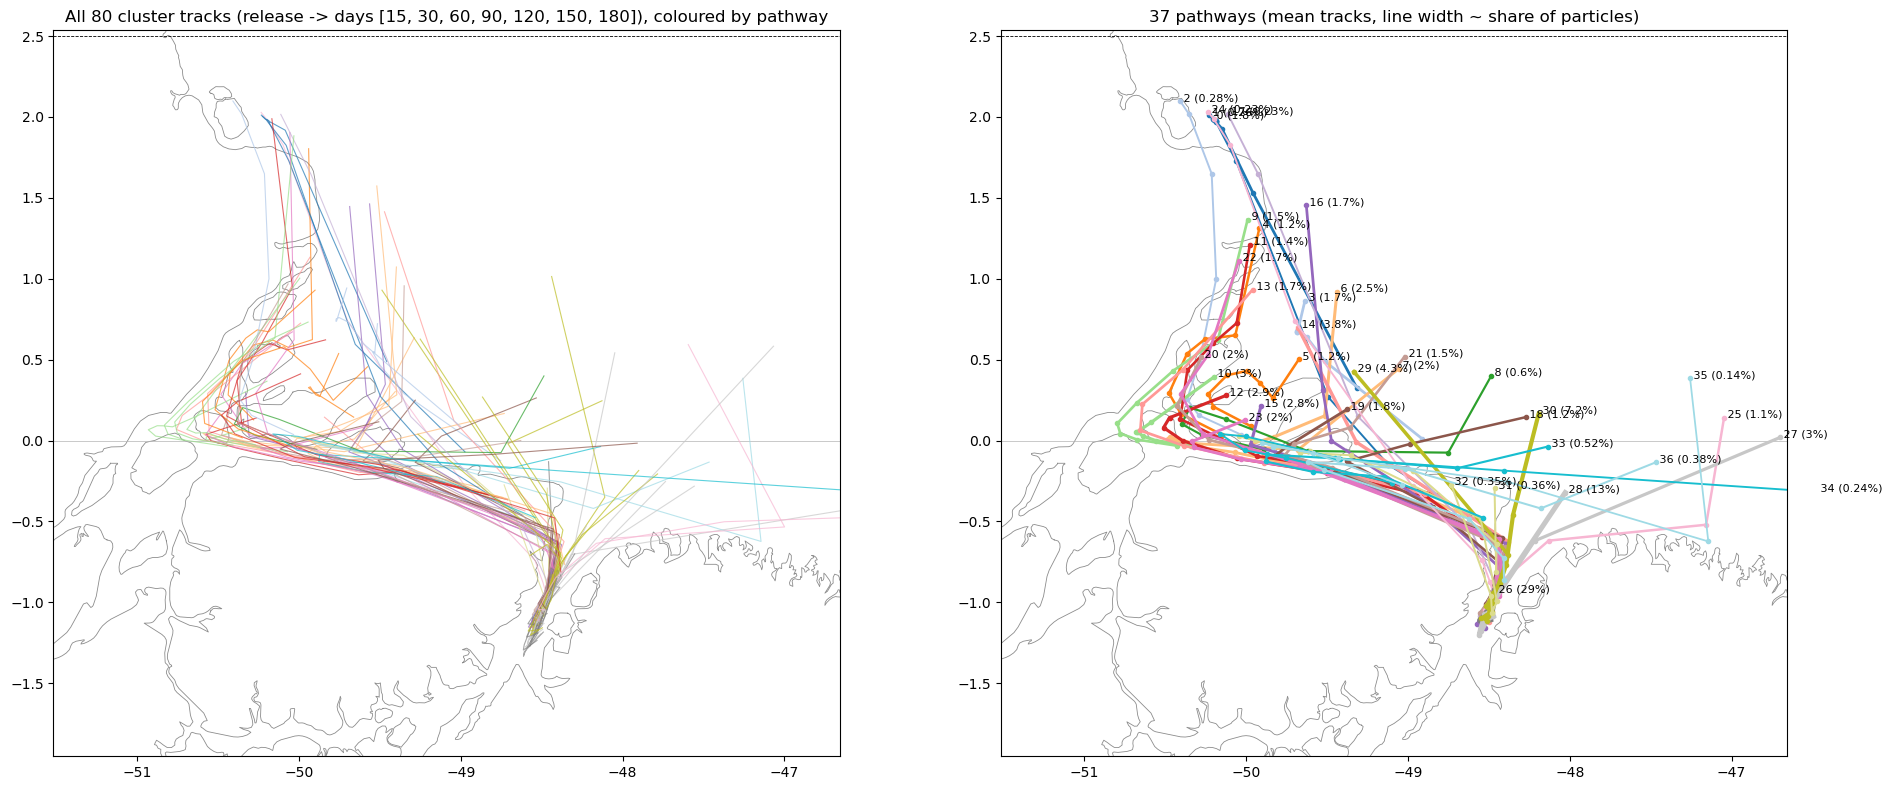

In [8]:
pcmap = plt.get_cmap("tab20", max(n_path, 3))
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
draw_coast(ax[0])
for c in range(K):
    lo, la = cl_track(c)
    ax[0].plot(lo, la, "-", color=pcmap(PATH_OF[c]), lw=.8, alpha=.7)
ax[0].set_title(f"All {K} cluster tracks (release -> days {DAYS_NC}), coloured by pathway")
draw_coast(ax[1])
for i in range(n_path):
    lo, la = pw_track(i)
    ax[1].plot(lo, la, ".-", color=pcmap(i), lw=1 + 4 * np.sqrt(share[i] / share.max()))
    ax[1].text(lo[-1], la[-1], f" {i} ({share[i]:.2g}%)", fontsize=8)
ax[1].set_title(f"{n_path} pathways (mean tracks, line width ~ share of particles)")
fig.tight_layout(); plt.show()

In [9]:
# persist the fit (only when SAVE_MODEL is True)
import joblib, json
if SAVE_MODEL:
    MODEL_DIR = C.MODELS_DIR / f"no_cross_1.7_k{K}"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(km, MODEL_DIR / f"kmeans_k{K}.pkl"); joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
    np.save(MODEL_DIR / "weights_W.npy", Wd); np.save(MODEL_DIR / "pathway_of_cluster.npy", PATH_OF)
    meta_ok[["trajectory_id", "store", "row", "traj", "release_time"]].assign(
        cluster=labels, pathway=PATH_OF[labels]).to_parquet(MODEL_DIR / "labels.parquet", index=False)
    (MODEL_DIR / "fit_metadata.json").write_text(json.dumps(dict(
        source_notebook="1.7_NoCross_clustering.ipynb", K=K, DAYS_NC=DAYS_NC,
        DAY_WEIGHTS_NC={str(k): v for k, v in wd.items()}, PATHWAY_SEP_KM=PATHWAY_SEP_KM,
        n_pathways=int(n_path), n_particles=int(len(X))), indent=2))
    print("saved ->", MODEL_DIR)
else:
    print("SAVE_MODEL is False -> nothing written")

SAVE_MODEL is False -> nothing written


## 6. Hierarchical view
Complete-linkage tree of the K cluster tracks (same distance as the
pathways). Left: the tree with the `PATHWAY_SEP_KM` cut; right: the clusters
coloured by the groups of a cut into `N_GROUPS` groups.

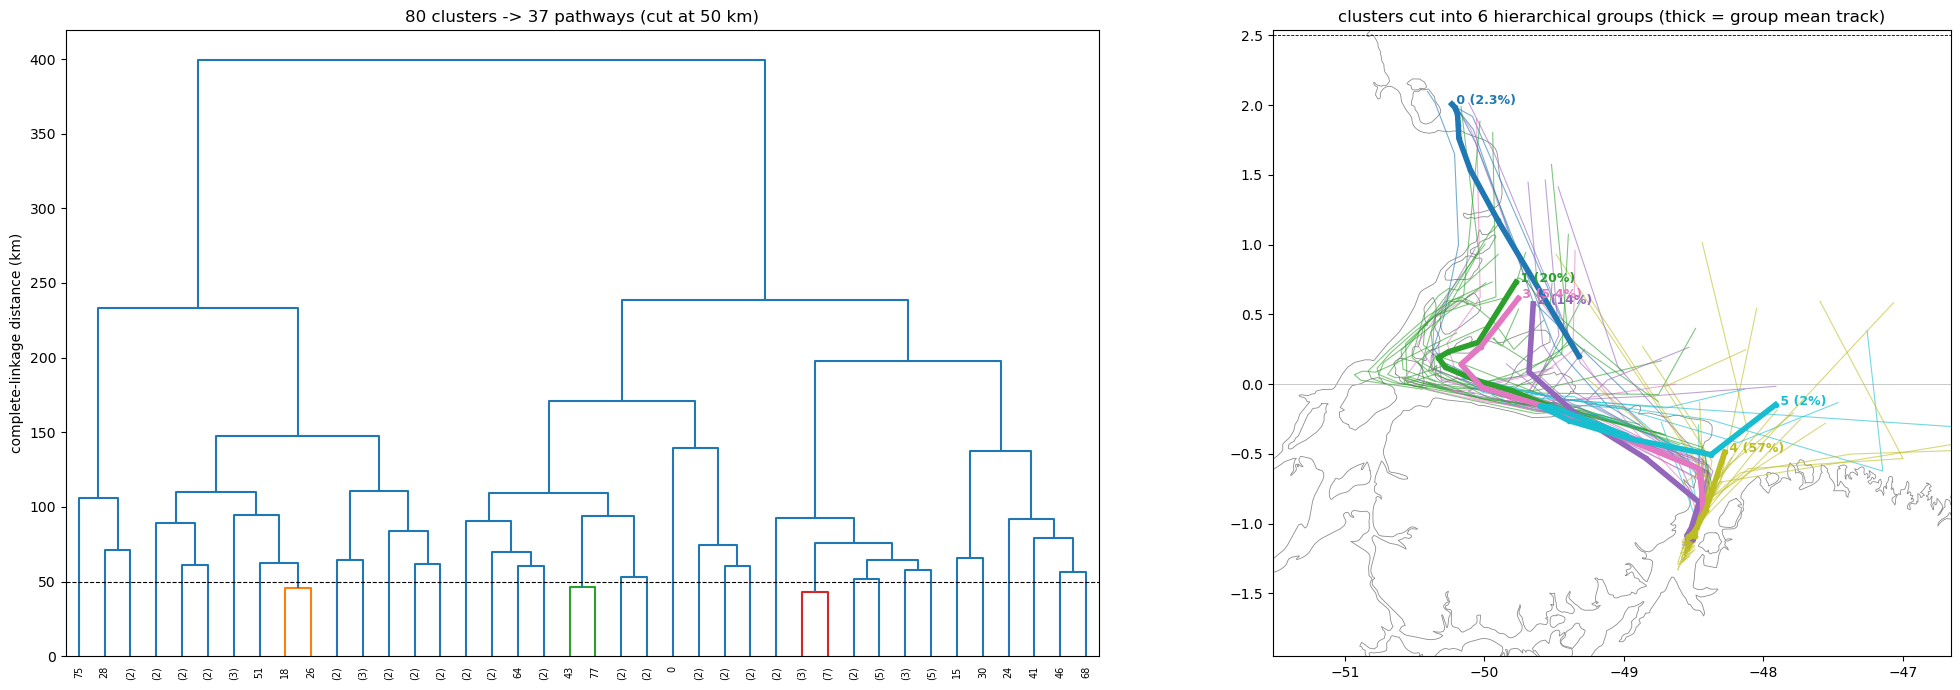

In [10]:
N_GROUPS = 6
Z = linkage(squareform(track_dist(cent_deg, cent_deg), checks=False), "complete")
hg = fcluster(Z, t=N_GROUPS, criterion="maxclust") - 1
fig, ax = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [1, 1.1]})
dendrogram(Z, ax=ax[0], truncate_mode="lastp", p=min(40, K), color_threshold=PATHWAY_SEP_KM,
           leaf_rotation=90, leaf_font_size=7)
ax[0].axhline(PATHWAY_SEP_KM, color="k", ls="--", lw=.8); ax[0].set_ylabel("complete-linkage distance (km)")
ax[0].set_title(f"{K} clusters -> {n_path} pathways (cut at {PATHWAY_SEP_KM} km)")
gcm = plt.get_cmap("tab10", max(N_GROUPS, 3))
draw_coast(ax[1])
for c in range(K):
    lo, la = cl_track(c)
    ax[1].plot(lo, la, "-", color=gcm(hg[c]), lw=.8, alpha=.6)
for gi in range(N_GROUPS):
    m = hg == gi
    tr = np.average(cent_deg[m], axis=0, weights=sizes[m])
    lo = np.r_[np.average(rel_lon[m], weights=sizes[m]), tr[1::2]]; la = np.r_[np.average(rel_lat[m], weights=sizes[m]), tr[0::2]]
    ax[1].plot(lo, la, ".-", color=gcm(gi), lw=4)
    ax[1].text(lo[-1], la[-1], f" {gi} ({share_cl[m].sum():.2g}%)", fontsize=9, fontweight="bold", color=gcm(gi))
ax[1].set_title(f"clusters cut into {N_GROUPS} hierarchical groups (thick = group mean track)")
fig.tight_layout(); plt.show()

## 7. Real tracks per pathway
Up to `TRACKS_PER_PANEL` random member particles of each pathway (all days),
with the pathway mean track in orange.

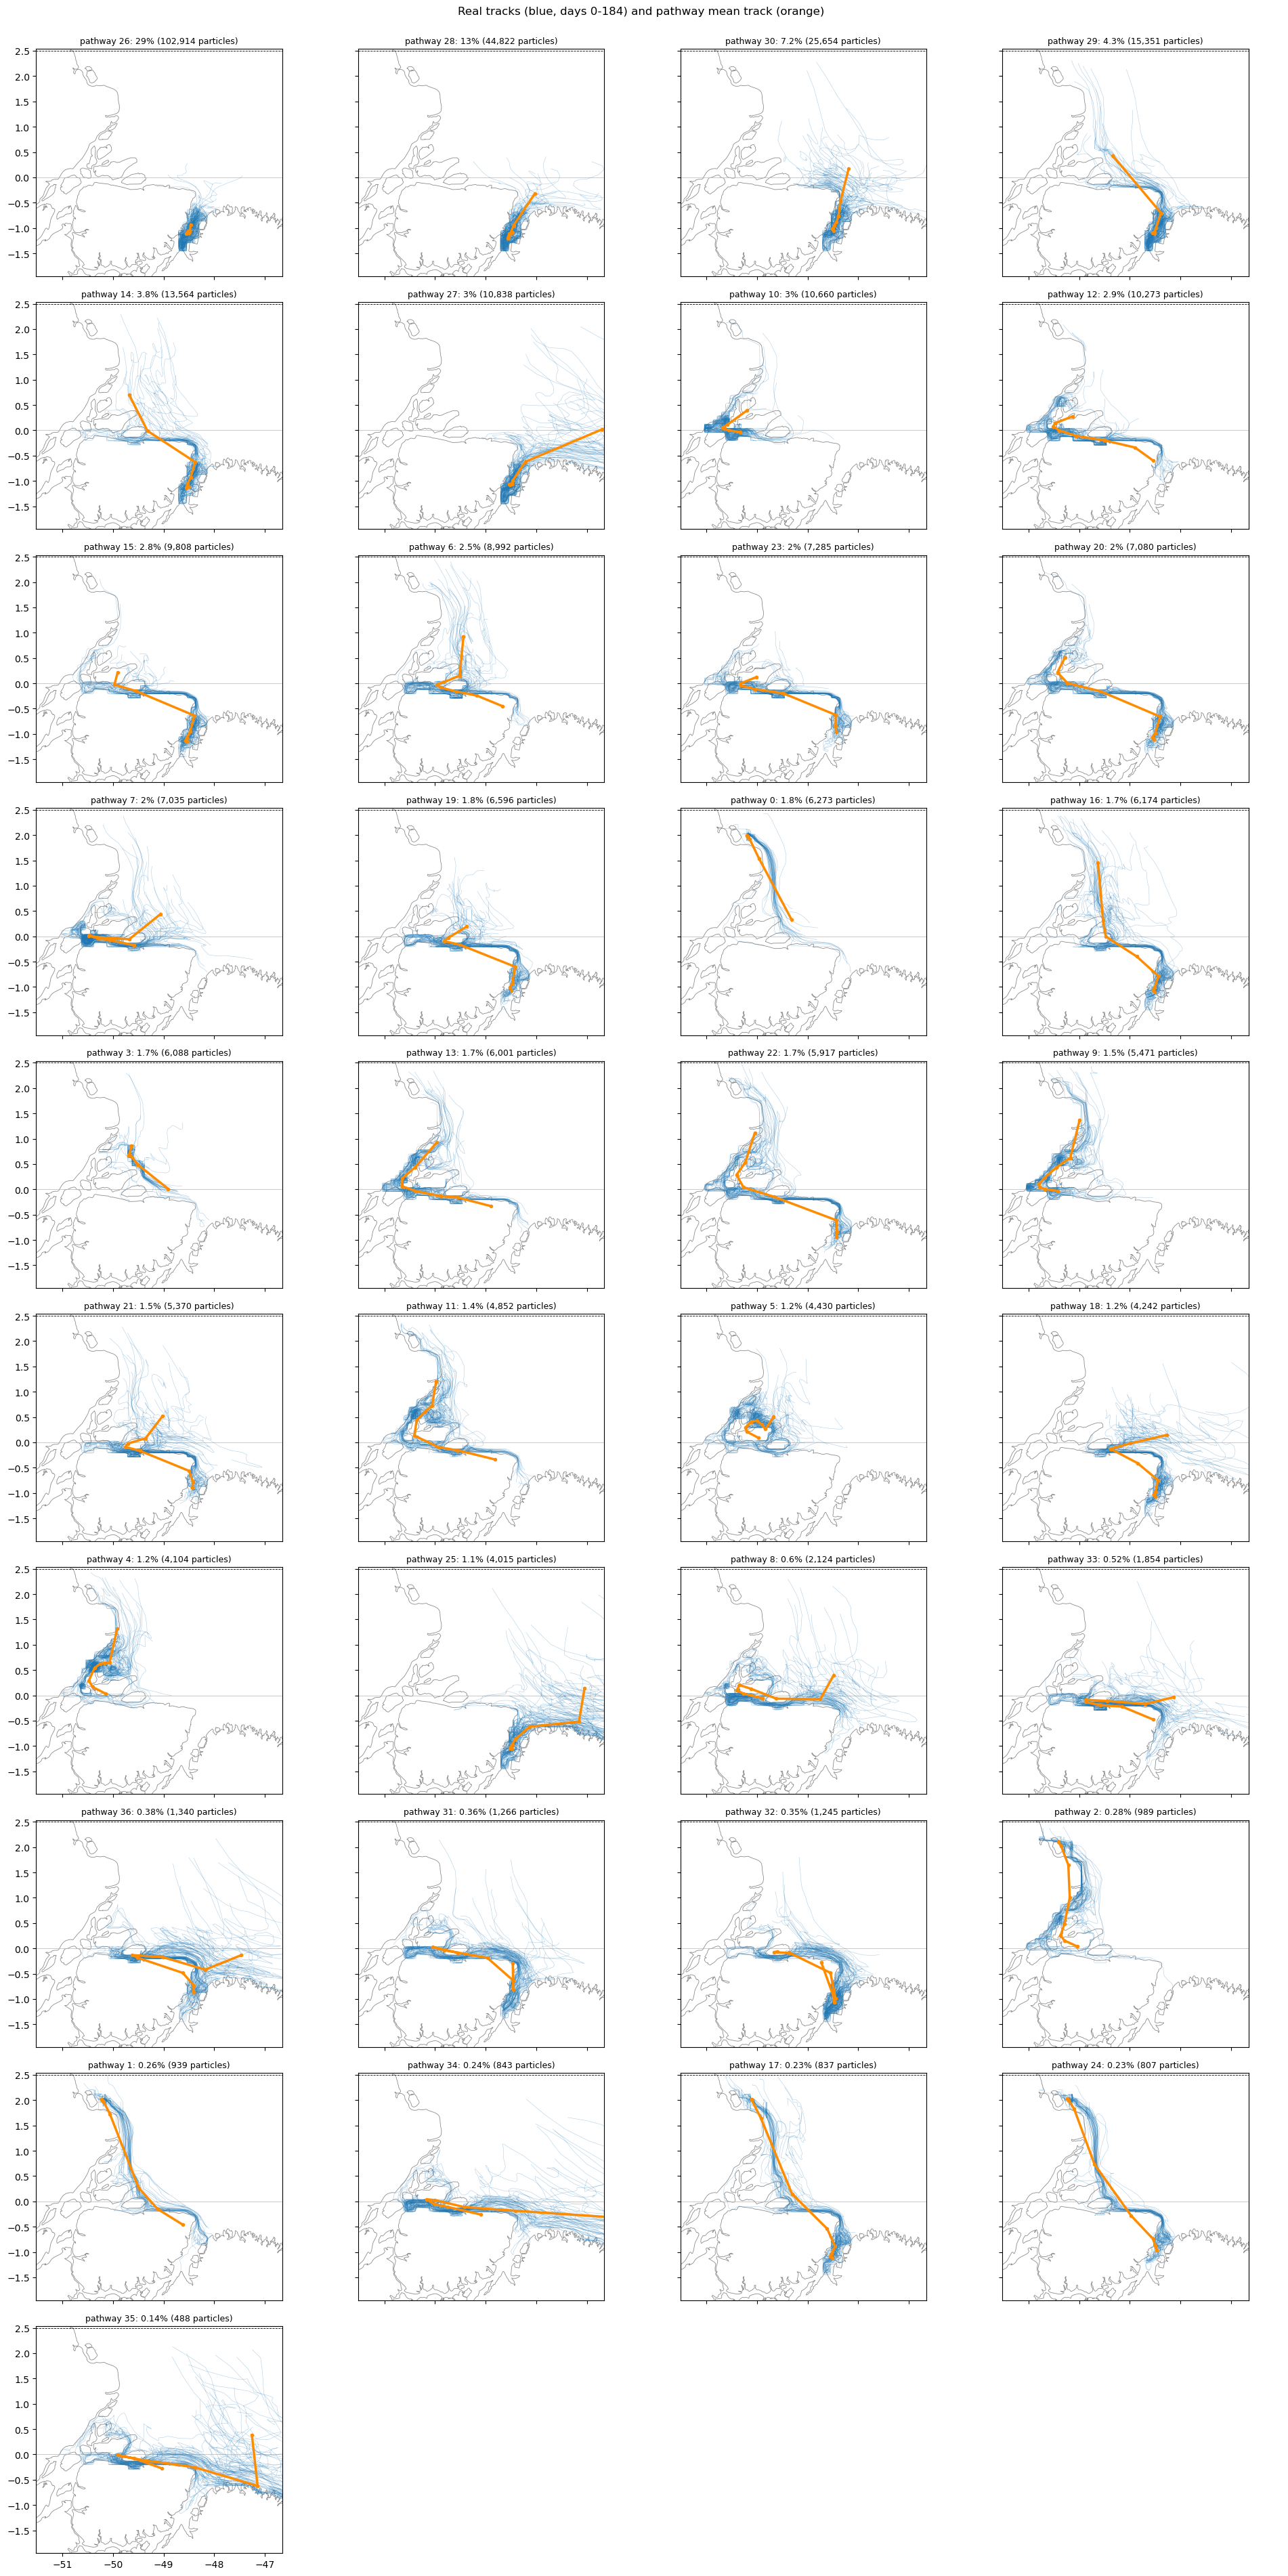

In [11]:
TRACKS_PER_PANEL = 40
rng = np.random.default_rng(0)
pw_lab = PATH_OF[labels]
order = np.argsort(-share)
ncol = 4; nrow = int(np.ceil(n_path / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.8 * ncol, 3.8 * nrow), squeeze=False, sharex=True, sharey=True)
for j, i in enumerate(order):
    ax = axes[j // ncol][j % ncol]
    draw_coast(ax)
    mem = np.where(pw_lab == i)[0]
    for r in rng.choice(mem, min(TRACKS_PER_PANEL, len(mem)), replace=False):
        ax.plot(LON_ok[r], LAT_ok[r], "-", color="tab:blue", lw=.4, alpha=.35)
    lo, la = pw_track(i)
    ax.plot(lo, la, ".-", color="darkorange", lw=2.5, zorder=3)
    ax.set_title(f"pathway {i}: {share[i]:.2g}% ({len(mem):,} particles)", fontsize=9)
for j in range(n_path, nrow * ncol):
    axes[j // ncol][j % ncol].axis("off")
fig.suptitle("Real tracks (blue, days 0-184) and pathway mean track (orange)", y=1.0)
fig.tight_layout(); plt.show()

## 8. Seasonality: which pathway, by release month
Share of each month's never-crossing particles in each pathway (only months
with at least 1,000 particles).

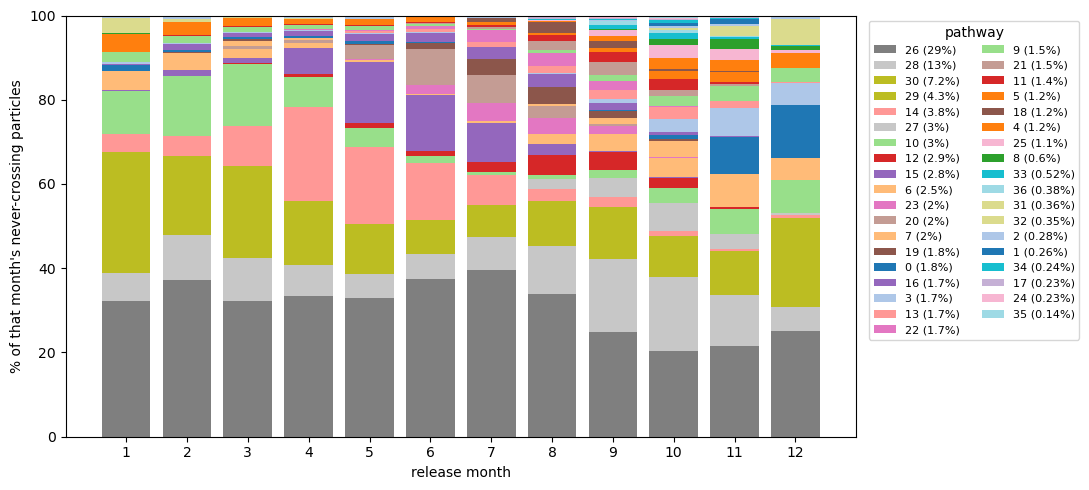

particles per release month: {1: 6557, 2: 3679, 3: 3898, 4: 5249, 5: 6699, 6: 14768, 7: 44383, 8: 81267, 9: 79914, 10: 58235, 11: 35429, 12: 16463}


In [12]:
mt = pd.crosstab(meta_ok.release_month, pw_lab)
mt = mt[mt.sum(axis=1) >= 1000]
mp = mt.div(mt.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(mp))
for i in order:
    vals = mp.get(i, pd.Series(0, index=mp.index)).to_numpy()
    ax.bar(mp.index.astype(str), vals, bottom=bottom, color=pcmap(i), label=f"{i} ({share[i]:.2g}%)")
    bottom += vals
ax.set_xlabel("release month"); ax.set_ylabel("% of that month's never-crossing particles")
ax.legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left", title="pathway")
fig.tight_layout(); plt.show()
print("particles per release month:", mt.sum(axis=1).to_dict())